In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (7352, 563)
Test shape: (2947, 563)


In [3]:
print(train.columns[-5:])            # last few column names
print(train.isnull().sum().sum())    # total missing values
train["Activity"].value_counts()

Index(['angle(X,gravityMean)', 'angle(Y,gravityMean)', 'angle(Z,gravityMean)',
       'subject', 'Activity'],
      dtype='str')
0


Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

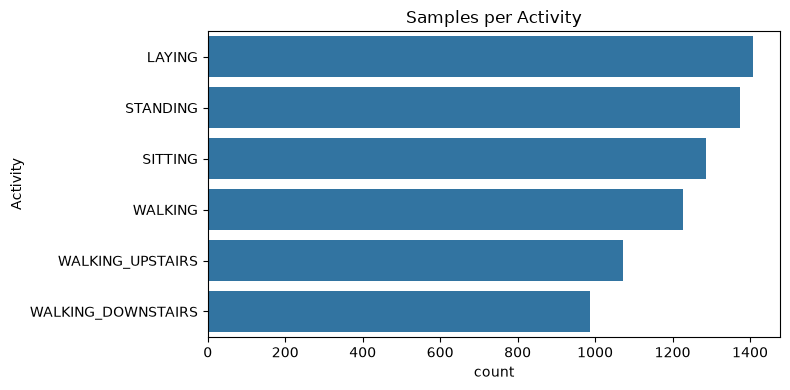

In [4]:
plt.figure(figsize=(8,4))
sns.countplot(y=train["Activity"], order=train["Activity"].value_counts().index)
plt.title("Samples per Activity")
plt.tight_layout()
plt.show()

In [5]:
X_train = train.drop(columns=["subject", "Activity"])
y_train = train["Activity"]
X_test = test.drop(columns=["subject", "Activity"])
y_test = test["Activity"]

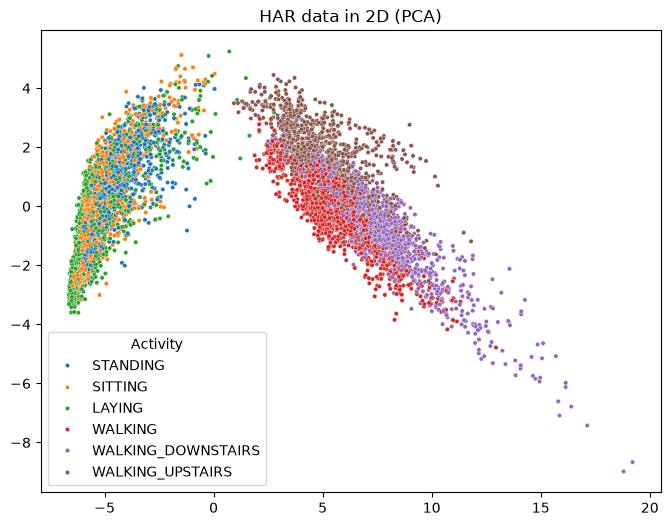

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_train)

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_2d[:,0], y=X_2d[:,1], hue=y_train, s=10, palette="tab10")
plt.title("HAR data in 2D (PCA)")
plt.savefig("pca_plot.png", dpi=150)
plt.show()

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

results = {}
for kernel in ["linear", "rbf", "poly", "sigmoid"]:
    start = time.time()
    model = SVC(kernel=kernel)
    model.fit(X_train_s, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_s))
    results[kernel] = acc
    print(f"{kernel:8s}  accuracy: {acc:.4f}  time: {time.time()-start:.1f}s")

linear    accuracy: 0.9606  time: 0.8s
rbf       accuracy: 0.9518  time: 2.4s
poly      accuracy: 0.9240  time: 1.9s
sigmoid   accuracy: 0.8721  time: 1.5s


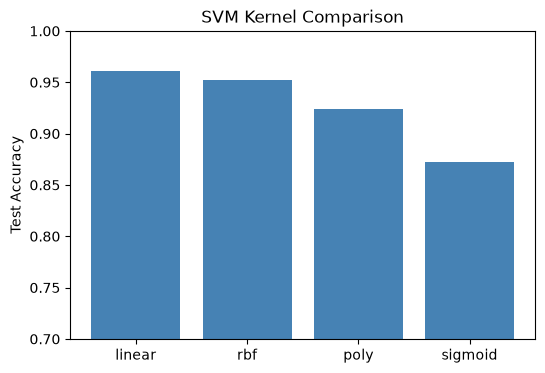

In [9]:
plt.figure(figsize=(6,4))
plt.bar(results.keys(), results.values(), color="steelblue")
plt.ylim(0.7, 1.0)
plt.ylabel("Test Accuracy")
plt.title("SVM Kernel Comparison")
plt.savefig("kernel_comparison.png", dpi=150)
plt.show()

In [10]:
from sklearn.model_selection import GridSearchCV

params = {
    "C": [1, 10, 100],
    "gamma": ["scale", 0.001, 0.0001]
}

grid = GridSearchCV(SVC(kernel="rbf"), params, cv=3, n_jobs=-1, verbose=1)
grid.fit(X_train_s, y_train)

print("Best params:", grid.best_params_)
print("Best CV score:", round(grid.best_score_, 4))

best_svm = grid.best_estimator_
print("Test accuracy:", accuracy_score(y_test, best_svm.predict(X_test_s)))

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best params: {'C': 100, 'gamma': 0.0001}
Best CV score: 0.9387
Test accuracy: 0.9562266711910418


In [11]:
params = {"C": [100, 300, 1000], "gamma": [0.0001, 0.00003, 0.00001]}
grid2 = GridSearchCV(SVC(kernel="rbf"), params, cv=3, n_jobs=-1)
grid2.fit(X_train_s, y_train)
print(grid2.best_params_, accuracy_score(y_test, grid2.predict(X_test_s)))

{'C': 1000, 'gamma': 3e-05} 0.9613165931455717


In [13]:
best_svm = grid2.best_estimator_

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.96      0.88      0.92       491
          STANDING       0.90      0.96      0.93       532
           WALKING       0.96      1.00      0.98       496
WALKING_DOWNSTAIRS       0.99      0.95      0.97       420
  WALKING_UPSTAIRS       0.97      0.96      0.97       471

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947



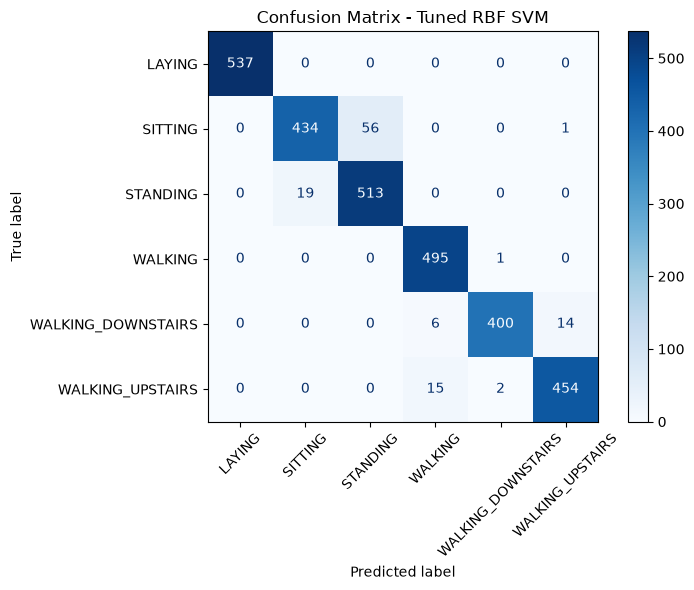

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred = best_svm.predict(X_test_s)
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=45, cmap="Blues")
plt.title("Confusion Matrix - Tuned RBF SVM")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [15]:
import joblib
joblib.dump(best_svm, "svm_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Saved!")

Saved!
